In [49]:
import pandas as pd
df = pd.read_csv('/Users/hanguyen/Documents/DATA ANALYTICS/IRONHACK/Week 5/Labs/lab-eda-bivariate/amz_uk_price_prediction_dataset.csv')

In [66]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [51]:
ct = pd.crosstab(df['category'], df['isBestSeller'])

In [52]:
ct

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [53]:
ct['best_seller_rate'] = (ct[True] / ct.sum(axis=1)) * 100

ct.sort_values('best_seller_rate', ascending=False)

isBestSeller,False,True,best_seller_rate
category,,,
Grocery,9008,556,5.813467
Smart Home Security & Lighting,98,6,5.769231
Health & Personal Care,9017,552,5.768628
Mobile Phone Accessories,248,11,4.247104
Power & Hand Tools,8353,306,3.533895
...,...,...,...
"CD, Disc & Tape Players",8798,0,0.000000
General Music-Making Accessories,259,0,0.000000
Snowboard Boots,1449,0,0.000000


In [54]:
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(ct)

print("Chi-square:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

Chi-square: 50603.56501614783
p-value: 0.0
Degrees of freedom: 590


In [55]:
import numpy as np

n = ct.to_numpy().sum()

r, k = ct.shape

cramers_v = np.sqrt(chi2 / (n * (min(r-1, k-1))))

print("Cramér's V:", cramers_v)

Cramér's V: 0.10175125266461912


In [ ]:
#Category does affect bestseller rate. But effect is weak

In [ ]:
df['']

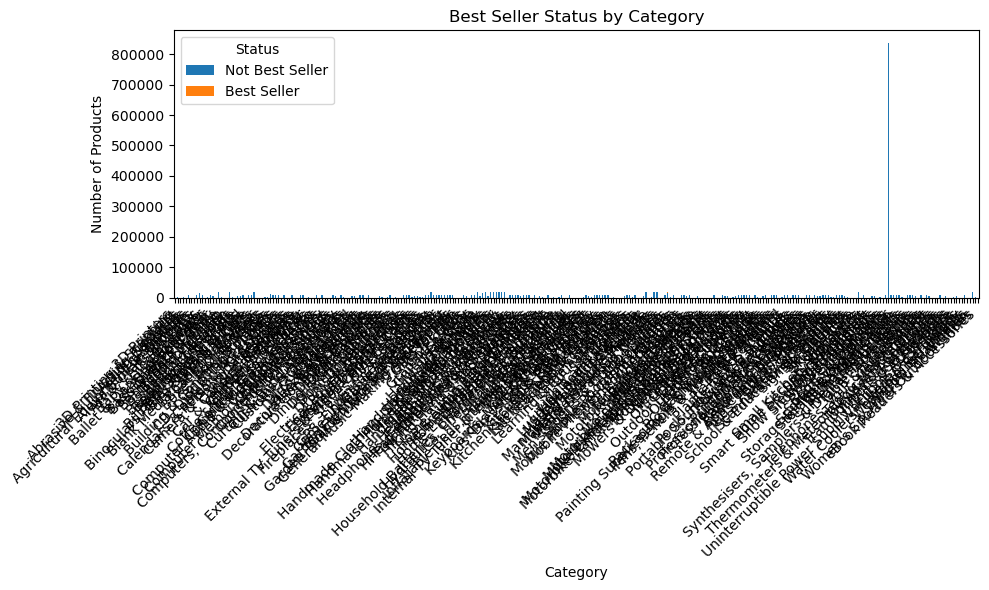

In [71]:
#Visualize the relationship between product categories and the best-seller status using a stacked bar chart.
# Count occurrences
counts = (
    df.groupby(['category', 'isBestSeller'])
      .size()
      .unstack(fill_value=0)
)

# Optional: rename columns for clarity
counts.columns = ['Not Best Seller', 'Best Seller']

# Plot stacked bar chart
counts.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.xlabel('Category')
plt.ylabel('Number of Products')
plt.title('Best Seller Status by Category')
plt.legend(title='Status')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.


In [5]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [7]:
#Calculate IQR for price

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1
print("IQR for price:", IQR)

IQR for price: 36.0


In [8]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [ ]:
#Remove outliers from price column
df_clean = df[
    (df['price'] >= lower_bound) &
    (df['price'] <= upper_bound)
].copy()

In [21]:
df['price'].describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

In [16]:
df_clean['price'].describe()

count    2.115963e+06
mean     2.340827e+01
std      2.051335e+01
min      0.000000e+00
25%      9.130000e+00
50%      1.599000e+01
75%      2.999000e+01
max      9.999000e+01
Name: price, dtype: float64

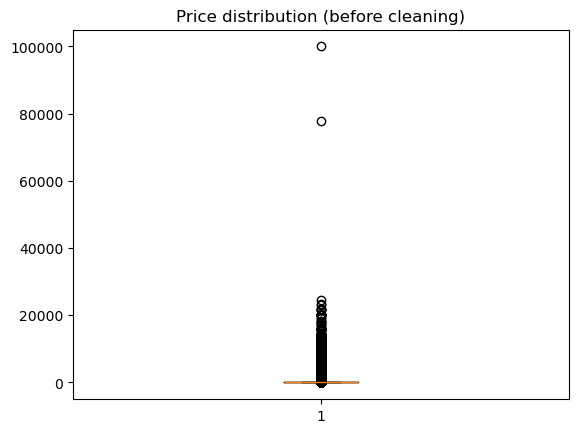

In [ ]:
plt.boxplot(df['price'], vert=True
            )
plt.title('Price distribution (before cleaning)')
plt.show()

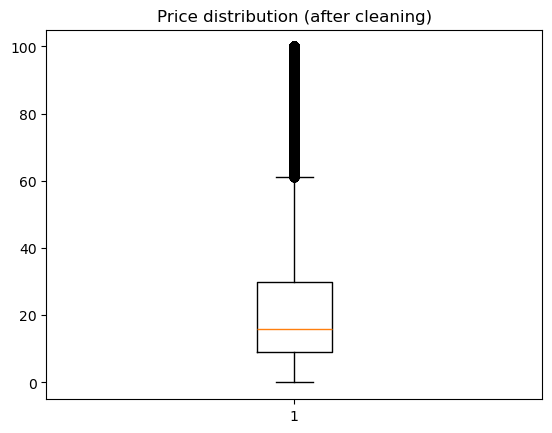

In [41]:
plt.boxplot(df_clean['price'], vert=True)
plt.title('Price distribution (after cleaning)')
plt.show()

In [23]:
df['category'].nunique()

296

In [11]:
top20 = (
    df['category']
    .value_counts()
    .head(20)
    .index
)
top20

Index(['Sports & Outdoors', 'Beauty', 'Handmade Clothing, Shoes & Accessories',
       'Bath & Body', 'Birthday Gifts', 'Manicure & Pedicure Products',
       'Skin Care', 'Make-up', 'Hair Care', 'Fragrances', 'Handmade Gifts',
       'Handmade Home Décor', 'Luggage and travel gear', 'Handmade Jewellery',
       'Handmade Artwork', 'Women', 'Handmade Home & Kitchen Products',
       'Handmade Kitchen & Dining', 'Men', 'Baby'],
      dtype='object', name='category')

In [13]:
df_top20 = df[df['category'].isin(top20)].copy()

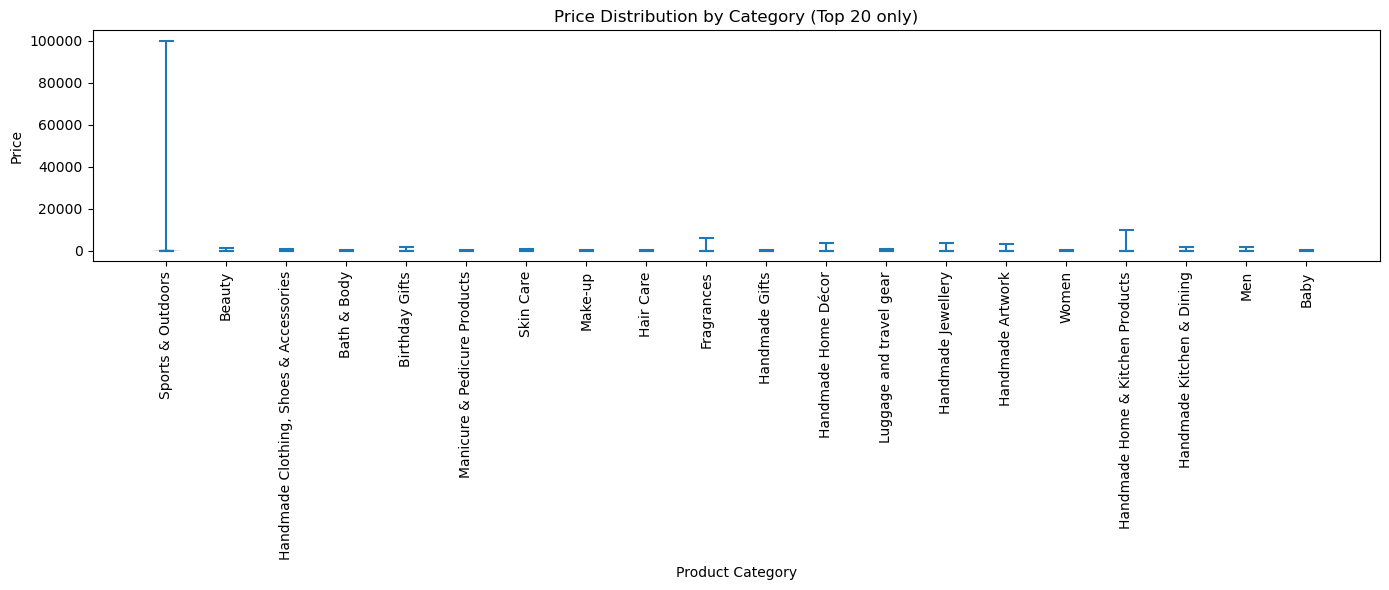

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

data = [
    df_top20[df_top20['category'] == cat]['price']
    for cat in top20
]

plt.violinplot(data, showmedians=True)

plt.xticks(range(1, len(top20) + 1), top20, rotation=90)
plt.xlabel('Product Category')
plt.ylabel('Price')
plt.title('Price Distribution by Category (Top 20 only)')

plt.tight_layout()
plt.show()

In [ ]:
#Which category has the highest median price? - Desktop PCs
df_clean.groupby('category')['price'].median().sort_values(ascending=False)

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

In [26]:
top10 = df_clean['category'].value_counts().head(10).index

In [29]:
avg_price = (
    df_clean[df_clean['category'].isin(top10)]
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

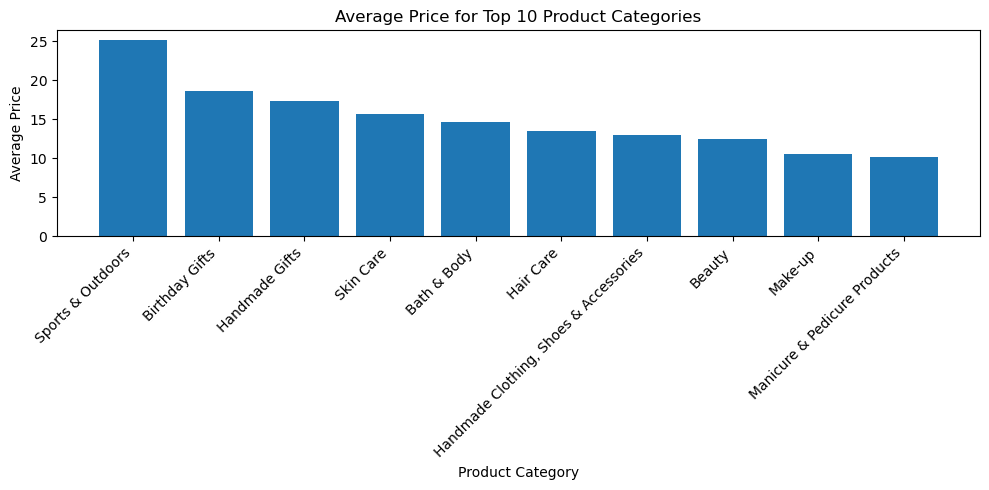

In [30]:
# Bar chart
plt.figure(figsize=(10, 5))

plt.bar(avg_price.index, avg_price.values)

plt.xlabel('Product Category')
plt.ylabel('Average Price')
plt.title('Average Price for Top 10 Product Categories')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [ ]:
#Which category has the highest mean price? - Motherboards 
df_clean.groupby('category')['price'].mean().sort_values(ascending=False)

category
Motherboards             68.772432
Boxing Shoes             67.417803
Desktop PCs              66.915562
Tablets                  66.552971
Graphics Cards           65.103509
                           ...    
Bedding Accessories       8.835220
Adapters                  8.750197
Signs & Plaques           8.210513
Arts & Crafts             8.006540
Office Paper Products     6.876369
Name: price, Length: 296, dtype: float64

In [33]:
df_top10 = df_clean[df_clean['category'].isin(top10)].copy()

In [36]:
data = [
    df_top10[df_top10['category'] == cat]['stars']
    for cat in top10
]
data

[82163      4.2
 82164      4.2
 82167      4.5
 82168      4.7
 82169      4.2
           ... 
 2429088    0.0
 2429089    0.0
 2429090    4.3
 2437153    4.2
 2437154    5.0
 Name: stars, Length: 694092, dtype: float64,
 814697     4.6
 814698     4.6
 814699     4.5
 814700     4.6
 814701     4.4
           ... 
 1867026    3.8
 1867027    4.4
 1867028    4.5
 1867029    2.1
 1867030    4.1
 Name: stars, Length: 19233, dtype: float64,
 612773    4.7
 612774    4.7
 612775    4.6
 612776    4.7
 612777    4.5
          ... 
 631860    4.7
 631861    4.0
 631862    4.6
 631863    3.8
 631864    4.7
 Name: stars, Length: 19050, dtype: float64,
 644030    4.5
 644031    4.5
 644032    4.4
 644033    4.6
 644034    4.8
          ... 
 662965    4.5
 662966    3.4
 662967    0.0
 662968    3.7
 662969    5.0
 Name: stars, Length: 18904, dtype: float64,
 1566904    4.8
 1566905    4.6
 1566906    4.6
 1566907    4.2
 1566908    4.5
           ... 
 1586128    4.2
 1586129    0.0
 1586130 

/var/folders/z1/hpkmqfl54717zbjq651n7__40000gn/T/ipykernel_35648/3194779110.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=top10, showfliers=False)


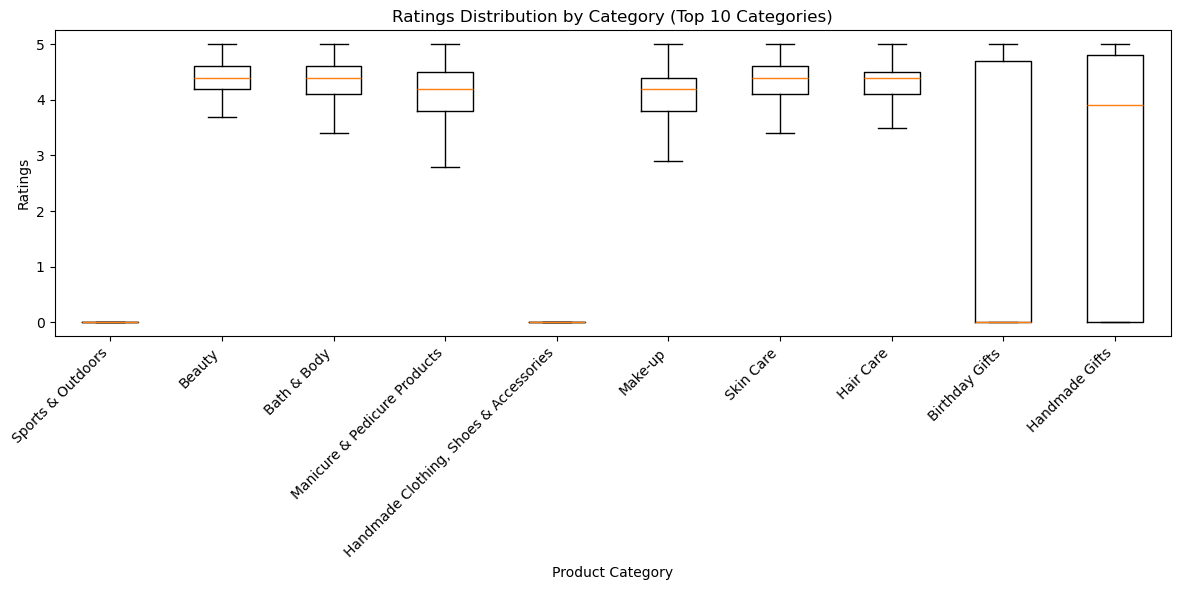

In [40]:
plt.figure(figsize=(12, 6))

plt.boxplot(data, labels=top10, showfliers=False)

plt.xlabel('Product Category')
plt.ylabel('Ratings')
plt.title('Ratings Distribution by Category (Top 10 Categories)')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [47]:
#Which category tends to receive the highest median rating from customers? Don't filter here by top categories.
df_clean.groupby('category')['stars'].median().sort_values(ascending=False)

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
                               ... 
Hockey Shoes                    0.0
Hi-Fi Receivers & Separates     0.0
Handmade Kitchen & Dining       0.0
Handmade Jewellery              0.0
eBook Readers & Accessories     0.0
Name: stars, Length: 296, dtype: float64

Part 3: Investigating the Interplay Between Product Prices and Ratings
Objective: Analyze how product ratings (stars) correlate with product prices.

Correlation Coefficients:

Calculate the correlation coefficient between price and stars.
Is there a significant correlation between product price and its rating?
Visualizations:

Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
Use a correlation heatmap to visualize correlations between all numerical variables.
Examine if product prices typically follow a normal distribution using a QQ plot.


In [57]:
#Calculate the correlation coefficient between price and stars.
correlation = df_clean['price'].corr(df_clean['stars'])

In [58]:
correlation

np.float64(-0.0776729987818131)

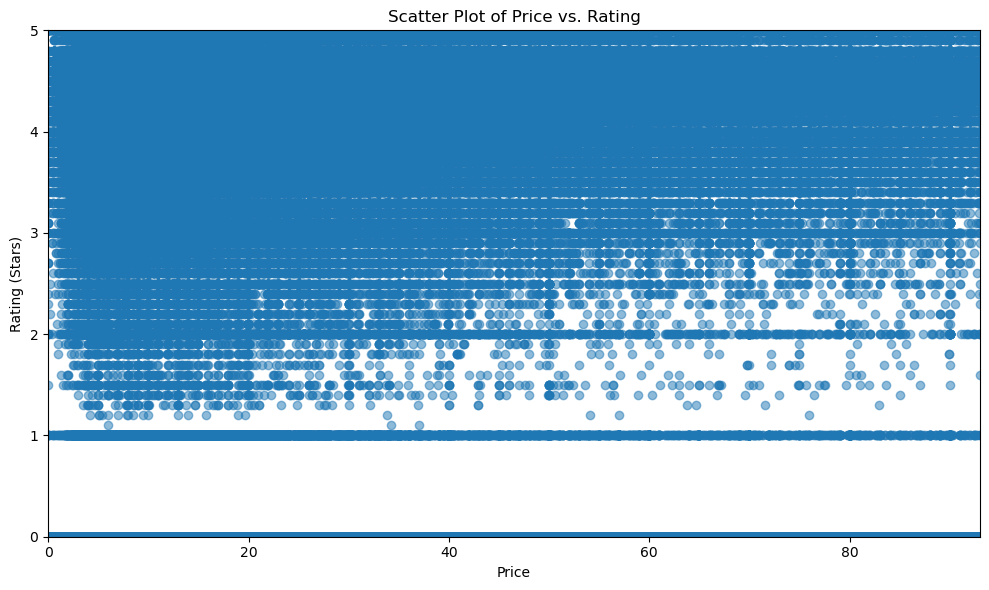

In [ ]:
#Use a scatter plot to visualize the relationship between product rating and price. - There is no clear relationship between price and rating.
plt.figure(figsize=(10, 6))
plt.scatter(df_clean['price'], df_clean['stars'], alpha=0.5)
plt.xlabel('Price')
plt.ylabel('Rating (Stars)')
plt.title('Scatter Plot of Price vs. Rating')
plt.xlim(0, df_clean['price'].quantile(0.99))
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

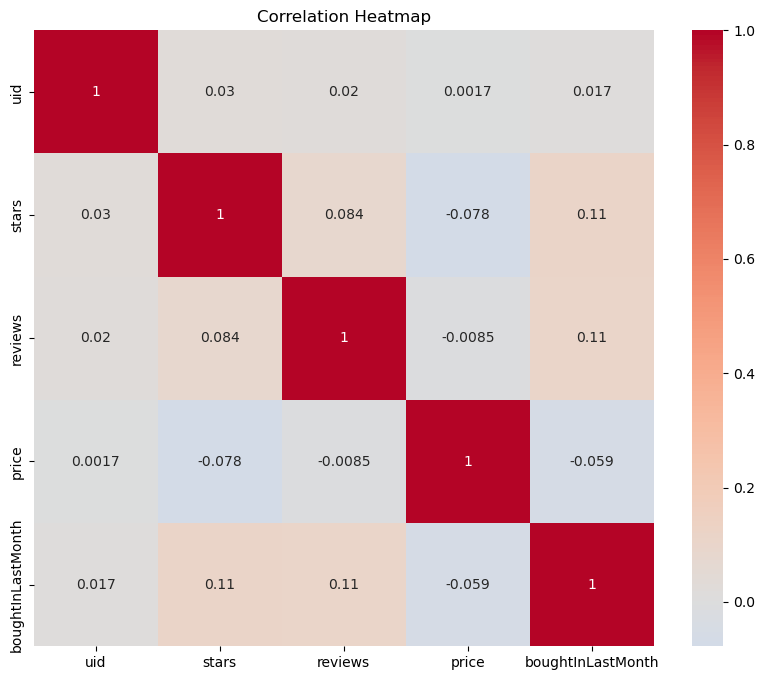

In [64]:
#Use a correlation heatmap to visualize correlations between all numerical variables.
import seaborn as sns   
numerical_cols = df_clean.select_dtypes(include=['float64', 'int64']).columns
correlation_matrix = df_clean[numerical_cols].corr()
# Create mask for upper triangle
#mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show() 

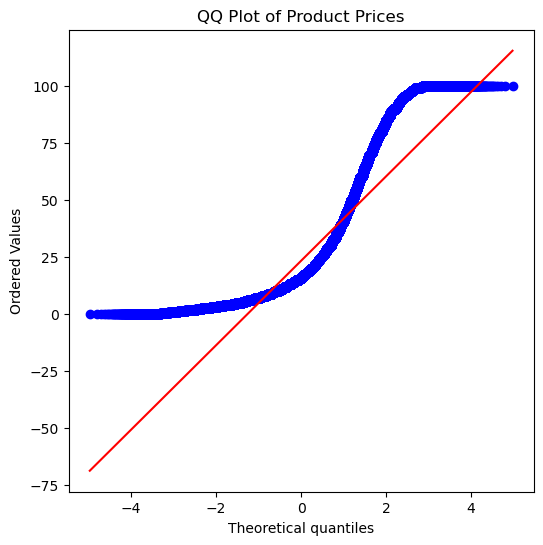

In [ ]:
#Examine if product prices typically follow a normal distribution using a QQ plot. - No, they do not follow a normal distribution.
import scipy.stats as stats
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 6))
stats.probplot(df_clean['price'], dist="norm", plot=plt)
plt.title('QQ Plot of Product Prices')
plt.show()